In [1]:
!pip install seaborn scikit-learn matplotlib pandas


Mounted at /content/drive

📥 Reading file: /content/drive/MyDrive/ML_OPS/nobroker_cleaned_data.csv

🔹 Basic Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56 entries, 0 to 55
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Title              56 non-null     object 
 1   Cost               56 non-null     float64
 2   Area               56 non-null     object 
 3   Furnishing Status  31 non-null     object 
 4   Property Type      56 non-null     object 
 5   Bathrooms          56 non-null     object 
 6   Amenities          56 non-null     object 
 7   Area_sqft          56 non-null     int64  
 8   Bathrooms_count    0 non-null      float64
 9   Rent_per_sqft      56 non-null     float64
dtypes: float64(3), int64(1), object(6)
memory usage: 4.5+ KB
None

🔹 First 5 rows:
                                               Title     Cost      Area  \
0  1 RK Apartment In Srila Towers For Rent In Hy

<ipython-input-2-11c2087aa9e9>:58: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Furnishing Status'].fillna('Not specified', inplace=True)


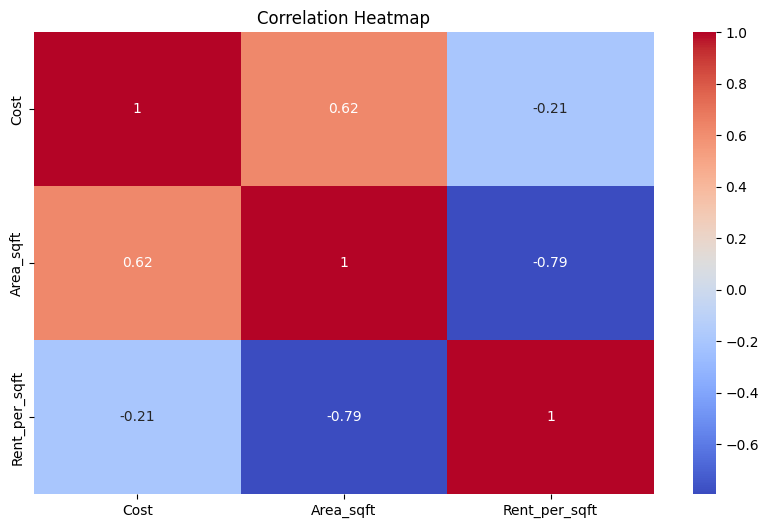


📝 Summary Statistics:

                                                    Title          Cost  \
count                                                  56     56.000000   
unique                                                 31           NaN   
top     1 RK Apartment In Srila Towers For Rent In Hyd...           NaN   
freq                                                    3           NaN   
mean                                                  NaN  20008.928571   
std                                                   NaN   4103.757781   
min                                                   NaN  10500.000000   
25%                                                   NaN  18000.000000   
50%                                                   NaN  20000.000000   
75%                                                   NaN  22250.000000   
max                                                   NaN  30000.000000   

              Area Furnishing Status  Property Type      Bathrooms  \
count

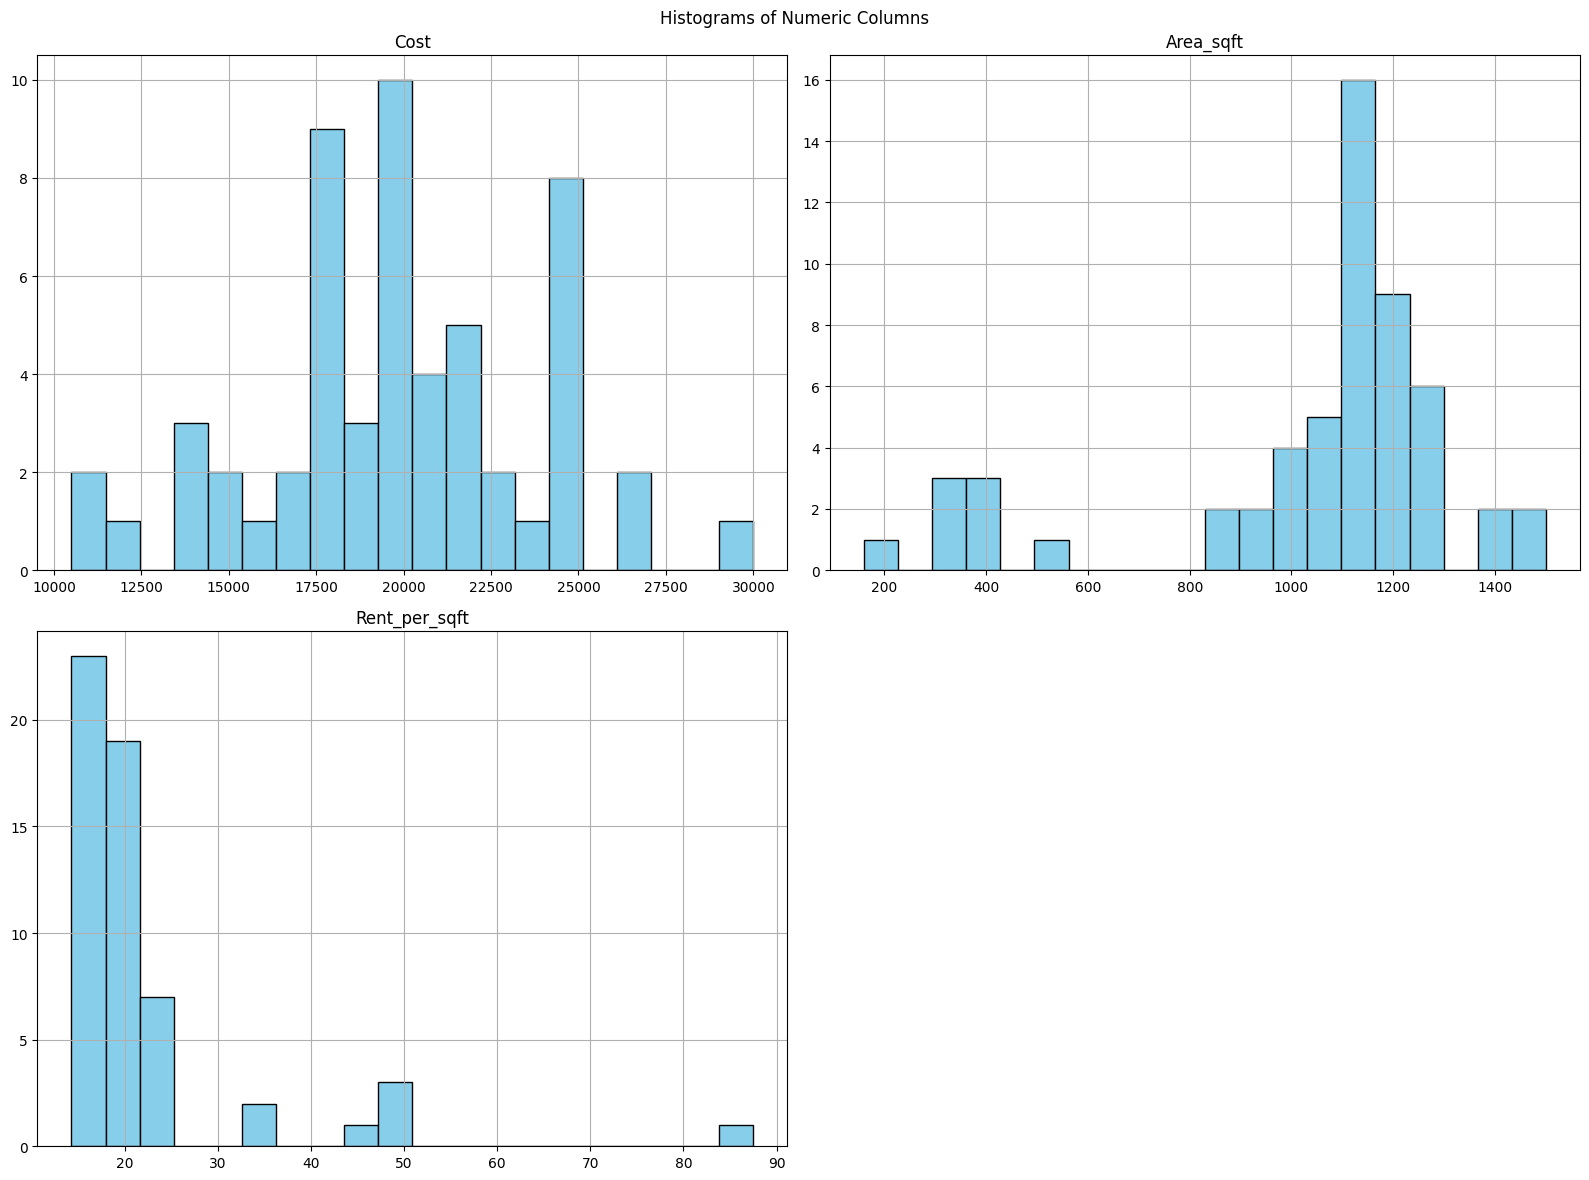

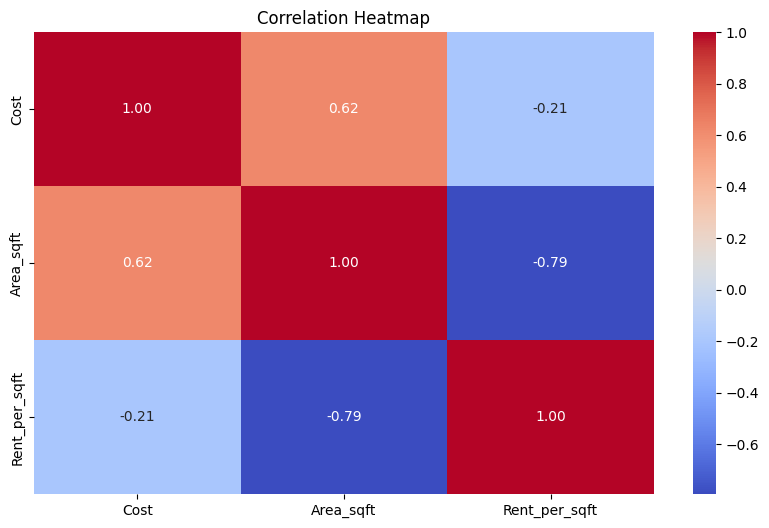

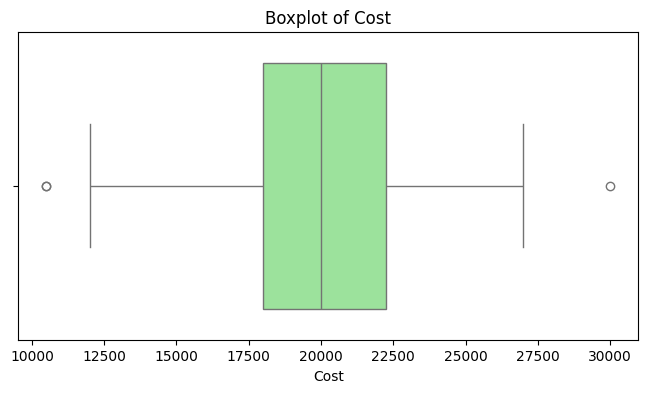

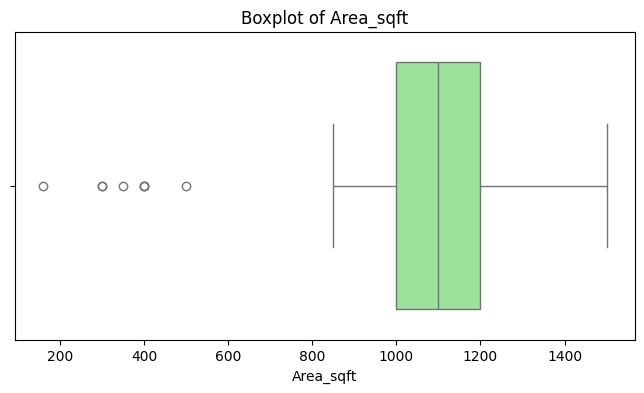

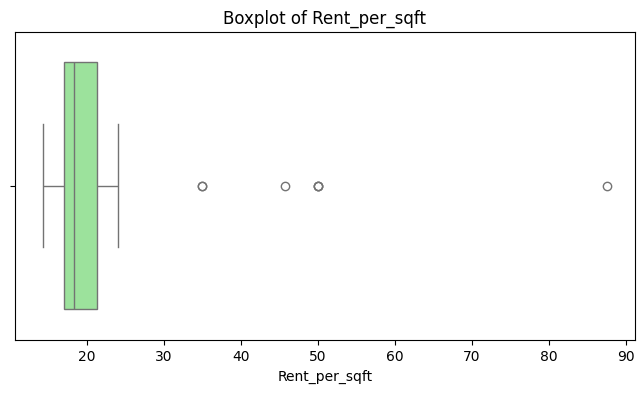

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# For Google Colab
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    file_path = '/content/drive/MyDrive/ML_OPS/nobroker_cleaned_data.csv'
else:
    file_path = 'c:/Users/apoor/OneDrive/Desktop/MLOps/nobroker_cleaned_data.csv'


def eda_report_basic(csv_file_path, na_values=None):
    if na_values is None:
        na_values = ["None", "none", "NA", "N/A", "n/a", "null", "NULL", "-", ""]

    print(f"\n📥 Reading file: {csv_file_path}")
    df = pd.read_csv(csv_file_path, na_values=na_values)

    # Basic Info
    print("\n🔹 Basic Info:")
    print(df.info())

    print("\n🔹 First 5 rows:")
    print(df.head())

    print("\n🔹 Shape:")
    print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

    # Summary Statistics
    print("\n🔹 Summary Statistics (Numeric):")
    print(df.describe())

    print("\n🔹 Summary Statistics (Categorical):")
    print(df.describe(include='object'))

    print("\n🔹 Column Types:")
    print(df.dtypes)

    print("\n🔹 Missing Values Per Column:")
    print(df.isnull().sum())

    print("\n🔹 Missing Values Per Row (first 10):")
    print(df.isnull().sum(axis=1).head(10))

    # Drop fully empty columns
    df = df.dropna(axis=1, how='all')

    # Fill known partial NaNs
    if 'Furnishing Status' in df.columns:
        df['Furnishing Status'].fillna('Not specified', inplace=True)

    # Drop any rows with remaining NaNs
    df = df.dropna()

    print("\n🔹 Shape after final cleaning (No NaNs):")
    print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

    # Confirm no missing values remain
    print("\n✅ Remaining NaN values (should be 0):")
    print(df.isnull().sum().sum())

    # Check for duplicates
    print("\n🔹 Number of Duplicate Rows:")
    print(df.duplicated().sum())

    # Correlation Heatmap
    plt.figure(figsize=(10, 6))
    sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm')
    plt.title("Correlation Heatmap")
    plt.show()

    return df


def eda_report_with_cleaning(df):
    print("\n📝 Summary Statistics:\n")
    print(df.describe(include='all'))

    print("\n🧼 Missing Values (Final Check):\n")
    print(df.isnull().sum())

    # Select valid numeric columns for plotting
    numeric_columns = df.select_dtypes(include='number').columns
    numeric_columns = [col for col in numeric_columns if df[col].nunique() > 1 and not df[col].isnull().all()]

    if not numeric_columns:
        print("⚠️ No suitable numeric columns for plotting.")
        return

    # Histograms
    df[numeric_columns].hist(bins=20, figsize=(16, 12), color='skyblue', edgecolor='black')
    plt.suptitle('Histograms of Numeric Columns')
    plt.tight_layout()
    plt.show()

    # Correlation Heatmap again
    plt.figure(figsize=(10, 6))
    sns.heatmap(df[numeric_columns].corr(), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap')
    plt.show()

    # Boxplots
    for col in numeric_columns:
        plt.figure(figsize=(8, 4))
        sns.boxplot(x=df[col], color='lightgreen')
        plt.title(f'Boxplot of {col}')
        plt.xlabel(col)
        plt.show()


# ✅ Run EDA
df_cleaned = eda_report_basic(file_path)
eda_report_with_cleaning(df_cleaned)
